0. Carga de datos y split

In [ ]:

import pandas as pd
import numpy as np

# Rutas relativas a los archivos que están en la raíz de tu repositorio
ruta_titanic = "Titanic-Dataset.csv"
ruta_telco = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

try:
    # Cargar los datasets
    df_titanic = pd.read_csv(ruta_titanic)
    df_telco = pd.read_csv(ruta_telco)
    
    print("¡Éxito! Datasets cargados correctamente.")
    print(f"Dimensiones Titanic: {df_titanic.shape}")
    print(f"Dimensiones Telco: {df_telco.shape}")
except FileNotFoundError as e:
    print(f"Error al cargar el archivo: {e}")
    print("Verifica que el nombre del archivo coincida exactamente con el explorador.")


¡Éxito! Datasets cargados correctamente.
Dimensiones Titanic: (891, 12)
Dimensiones Telco: (7043, 21)


In [2]:
from sklearn.model_selection import train_test_split

# --- Titanic: objetivo "Survived" ---
X_titanic = df_titanic.drop(columns=["Survived"])
y_titanic = df_titanic["Survived"]

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_titanic, y_titanic,
    test_size=0.2, random_state=42, stratify=y_titanic
)

print("TITANIC -> Train:", X_train_t.shape, "| Test:", X_test_t.shape)
print("% sobrevivientes en train:", round(y_train_t.mean() * 100, 1))
print("% sobrevivientes en test: ", round(y_test_t.mean() * 100, 1))

# --- Telco: objetivo "Churn" ---
X_telco = df_telco.drop(columns=["Churn"])
y_telco = df_telco["Churn"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_telco, y_telco,
    test_size=0.2, random_state=42, stratify=y_telco
)

print("\nTELCO -> Train:", X_train_c.shape, "| Test:", X_test_c.shape)
print(y_train_c.value_counts(normalize=True).round(3))
print(y_test_c.value_counts(normalize=True).round(3))

TITANIC -> Train: (712, 11) | Test: (179, 11)
% sobrevivientes en train: 38.3
% sobrevivientes en test:  38.5

TELCO -> Train: (5634, 20) | Test: (1409, 20)
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


1. Detección de outliers (antes)

In [3]:
import pandas as pd
import numpy as np

# Telco: TotalCharges viene como texto; los espacios vacíos pasan a NaN
for d in (X_train_c, X_test_c):
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")

print("NaN en TotalCharges (train):", X_train_c["TotalCharges"].isna().sum())

def resumen_outliers(serie, nombre, p_bajo=1, p_alto=99, factor=1.5):
    s = serie.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    iqr_inf, iqr_sup = q1 - factor * iqr, q3 + factor * iqr
    per_inf, per_sup = s.quantile(p_bajo / 100), s.quantile(p_alto / 100)
    n_iqr = ((s < iqr_inf) | (s > iqr_sup)).sum()
    n_per = ((s < per_inf) | (s > per_sup)).sum()
    return {
        "variable": nombre,
        "min": s.min(), "max": s.max(),
        "IQR_inf": round(iqr_inf, 2), "IQR_sup": round(iqr_sup, 2),
        "outliers_IQR": n_iqr, "%_IQR": round(100 * n_iqr / len(s), 2),
        "P1": round(per_inf, 2), "P99": round(per_sup, 2),
        "outliers_perc": n_per, "%_perc": round(100 * n_per / len(s), 2),
    }

tabla = pd.DataFrame([
    resumen_outliers(X_train_t["Age"], "Titanic - Age"),
    resumen_outliers(X_train_t["Fare"], "Titanic - Fare"),
    resumen_outliers(X_train_c["MonthlyCharges"], "Telco - MonthlyCharges"),
    resumen_outliers(X_train_c["TotalCharges"], "Telco - TotalCharges"),
])
tabla

NaN en TotalCharges (train): 8


,variable,min,max,IQR_inf,IQR_sup,outliers_IQR,%_IQR,P1,P99,outliers_perc,%_perc
0,Titanic - Age,0.42,80.0000,-6.00,66.00,6,1.04,0.98,67.04,12,2.09
1,Titanic - Fare,0.00,512.3292,-26.76,65.66,91,12.78,0.00,227.52,7,0.98
2,Telco - MonthlyCharges,18.40,118.7500,-45.84,171.51,0,0.00,19.20,114.98,107,1.90
3,Telco - TotalCharges,18.85,8684.8000,-4739.73,8985.62,0,0.00,19.90,8040.22,112,1.99


In [4]:
print(tabla.to_string(index=False))

              variable   min       max  IQR_inf  IQR_sup  outliers_IQR  %_IQR    P1     P99  outliers_perc  %_perc
         Titanic - Age  0.42   80.0000    -6.00    66.00             6   1.04  0.98   67.04             12    2.09
        Titanic - Fare  0.00  512.3292   -26.76    65.66            91  12.78  0.00  227.52              7    0.98
Telco - MonthlyCharges 18.40  118.7500   -45.84   171.51             0   0.00 19.20  114.98            107    1.90
  Telco - TotalCharges 18.85 8684.8000 -4739.73  8985.62             0   0.00 19.90 8040.22            112    1.99


2. Verificación de Fare == 0

In [5]:
# Verificación: ¿qué son los pasajeros con Fare == 0? (solo train)
ceros = X_train_t[X_train_t["Fare"] == 0]

print("Cantidad de Fare == 0 en train:", len(ceros))
print("\nPor clase (Pclass):")
print(ceros["Pclass"].value_counts())
print("\nPor puerto (Embarked):")
print(ceros["Embarked"].value_counts(dropna=False))
print("\nPor sexo:")
print(ceros["Sex"].value_counts())
print("\nAge nulos entre ellos:", ceros["Age"].isna().sum())
print()
print(ceros[["Name", "Sex", "Age", "Pclass", "Embarked"]].to_string())

Cantidad de Fare == 0 en train: 14

Por clase (Pclass):
Pclass
2    6
1    5
3    3
Name: count, dtype: int64

Por puerto (Embarked):
Embarked
S    14
Name: count, dtype: int64

Por sexo:
Sex
male    14
Name: count, dtype: int64

Age nulos entre ellos: 8

                                 Name   Sex   Age  Pclass Embarked
481  Frost, Mr. Anthony Wood "Archie"  male   NaN       2        S
302   Johnson, Mr. William Cahoone Jr  male  19.0       3        S
732              Knight, Mr. Robert J  male   NaN       2        S
179               Leonard, Mr. Lionel  male  36.0       3        S
633     Parr, Mr. William Henry Marsh  male   NaN       1        S
466             Campbell, Mr. William  male   NaN       2        S
674        Watson, Mr. Ennis Hastings  male   NaN       2        S
597               Johnson, Mr. Alfred  male  49.0       3        S
815                  Fry, Mr. Richard  male   NaN       1        S
413    Cunningham, Mr. Alfred Fleming  male   NaN       2        S
263    

In [ ]:
print("Supervivencia con Fare == 0:", round(y_train_t.loc[ceros.index].mean() * 100, 1), "%")
print("Supervivencia general en train:", round(y_train_t.mean() * 100, 1), "%")


# Conclusión: los 14 casos con Fare == 0 son todos hombres de Southampton en las 3 clases,
# 8 con Age nulo. Parecen un grupo real (tarifa no pagada), no errores de captura.
# Decisión: no se tratan como outliers ni como faltantes. Winsorización solo en cola superior.

Supervivencia con Fare == 0: 0.0 %
Supervivencia general en train: 38.3 %


3. Clase Winsorizador

In [11]:
# [Asistido por IA - Gemini, revisado]
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class Winsorizador(BaseEstimator, TransformerMixin):
    def __init__(self, columnas=None, metodo="iqr", factor=1.5,
                 percentil=99, colas="superior"):
        self.columnas = columnas
        self.metodo = metodo
        self.factor = factor
        self.percentil = percentil
        self.colas = colas

    def fit(self, X, y=None):
        if self.metodo not in ("iqr", "percentil"):
            raise ValueError("metodo debe ser 'iqr' o 'percentil'")
        if self.colas not in ("superior", "ambas"):
            raise ValueError("colas debe ser 'superior' o 'ambas'")

        X_df = pd.DataFrame(X)
        cols = (list(self.columnas) if self.columnas is not None
                else X_df.select_dtypes(include=[np.number]).columns.tolist())
        faltantes = [c for c in cols if c not in X_df.columns]
        if faltantes:
            raise ValueError(f"Columnas no encontradas: {faltantes}")

        self.cols_a_procesar_ = cols
        self.columnas_entrada_ = np.asarray(X_df.columns, dtype=object)
        self.limites_ = {}   # se reinicia en cada fit

        for col in cols:
            serie = X_df[col].to_numpy(dtype=float)   # los NaN se ignoran abajo
            if self.metodo == "iqr":
                q1, q3 = np.nanquantile(serie, [0.25, 0.75])
                iqr = q3 - q1
                lim_inf, lim_sup = q1 - self.factor * iqr, q3 + self.factor * iqr
            else:
                lim_inf = np.nanquantile(serie, (100 - self.percentil) / 100)
                lim_sup = np.nanquantile(serie, self.percentil / 100)
            self.limites_[col] = {
                "inf": lim_inf if self.colas == "ambas" else -np.inf,
                "sup": lim_sup,
            }
        return self

    def transform(self, X):
        check_is_fitted(self, "limites_")
        X_df = pd.DataFrame(X).copy()
        faltantes = [c for c in self.cols_a_procesar_ if c not in X_df.columns]
        if faltantes:
            raise ValueError(f"Columnas no encontradas al transformar: {faltantes}")
        for col, lim in self.limites_.items():
            X_df[col] = X_df[col].clip(lower=lim["inf"], upper=lim["sup"])  # NaN intactos
        return X_df

    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        return self.columnas_entrada_

4. Aplicación a Titanic y Telco

In [12]:
# [Asistido por IA - Gemini]
# Instanciar transformadores
wins_titanic_iqr = Winsorizador(columnas=['Fare', 'Age'], metodo='iqr', factor=1.5, colas='superior')
wins_titanic_p99 = Winsorizador(columnas=['Fare', 'Age'], metodo='percentil', percentil=99, colas='superior')

wins_telco_iqr = Winsorizador(columnas=['MonthlyCharges'], metodo='iqr', factor=1.5, colas='superior')
wins_telco_p99 = Winsorizador(columnas=['MonthlyCharges'], metodo='percentil', percentil=99, colas='superior')

# Ajustar y transformar Train
X_train_t_iqr = wins_titanic_iqr.fit_transform(X_train_t)
X_train_t_p99 = wins_titanic_p99.fit_transform(X_train_t)

X_train_c_iqr = wins_telco_iqr.fit_transform(X_train_c)
X_train_c_p99 = wins_telco_p99.fit_transform(X_train_c)

# Transformar Test (sin ajustar)
X_test_t_iqr = wins_titanic_iqr.transform(X_test_t)
X_test_t_p99 = wins_titanic_p99.transform(X_test_t)
X_test_c_iqr = wins_telco_iqr.transform(X_test_c)
X_test_c_p99 = wins_telco_p99.transform(X_test_c)

def resumen_limites(nombre, wins, X_tr, X_te):
    print(f"\n{nombre}")
    for col, lim in wins.limites_.items():
        n_tr = int((X_tr[col] > lim["sup"]).sum())
        n_te = int((X_te[col] > lim["sup"]).sum())
        print(f"  {col}: límite sup = {lim['sup']:.2f} | recortados train = {n_tr} | test = {n_te}")

resumen_limites("Titanic IQR 1.5", wins_titanic_iqr, X_train_t, X_test_t)
resumen_limites("Titanic P99",     wins_titanic_p99, X_train_t, X_test_t)
resumen_limites("Telco IQR 1.5",   wins_telco_iqr,   X_train_c, X_test_c)
resumen_limites("Telco P99",       wins_telco_p99,   X_train_c, X_test_c)


Titanic IQR 1.5
  Fare: límite sup = 65.66 | recortados train = 91 | test = 25
  Age: límite sup = 66.00 | recortados train = 6 | test = 1

Titanic P99
  Fare: límite sup = 227.53 | recortados train = 7 | test = 4
  Age: límite sup = 67.04 | recortados train = 6 | test = 1

Telco IQR 1.5
  MonthlyCharges: límite sup = 171.51 | recortados train = 0 | test = 0

Telco P99
  MonthlyCharges: límite sup = 114.98 | recortados train = 57 | test = 8


5. Verificación anti-fuga

In [13]:
# [Asistido por IA - Gemini, revisado]
def lim_iqr(s, f=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + f * (q3 - q1)

lim_clase = wins_titanic_iqr.limites_["Fare"]["sup"]          # lo que realmente se aplicó
lim_train = lim_iqr(X_train_t["Fare"])                        # recalculado solo con train
lim_todo  = lim_iqr(pd.concat([X_train_t, X_test_t])["Fare"]) # SOLO ilustrativo: así se vería la fuga

print(f"Límite aprendido por la clase : {lim_clase:.4f}")
print(f"Recalculado solo con train    : {lim_train:.4f}")
print(f"Con todo el dataset (ilustra) : {lim_todo:.4f}  (diferencia: {abs(lim_todo - lim_clase):.4f})")

# 1) La clase usó solo train
assert np.isclose(lim_clase, lim_train), "La clase NO usó solo train"

# 2) El test se recortó con el límite de TRAIN (no con uno propio)
esperado = min(X_test_t["Fare"].max(), lim_clase)
assert np.isclose(X_test_t_iqr["Fare"].max(), esperado), "El test no usó el límite de train"

# 3) Integridad: filas, índice, NaN y ceros intactos, original sin modificar
for orig, trans in [(X_train_t, X_train_t_iqr), (X_test_t, X_test_t_iqr)]:
    assert orig.shape == trans.shape and orig.index.equals(trans.index)
    assert orig["Age"].isna().sum() == trans["Age"].isna().sum()
    assert (orig["Fare"] == 0).sum() == (trans["Fare"] == 0).sum()
assert X_train_t["Fare"].max() > lim_clase     # el DataFrame original no se modificó
print("Verificaciones anti-fuga e integridad: OK")

Límite aprendido por la clase : 65.6563
Recalculado solo con train    : 65.6563
Con todo el dataset (ilustra) : 65.6344  (diferencia: 0.0219)
Verificaciones anti-fuga e integridad: OK


6. Comparación estadística

In [14]:
# [Asistido por IA - Gemini, revisado]
def generar_comparacion(original, escenarios, limites, columna):
    """original: DataFrame sin tratar (train). escenarios: {nombre: DataFrame winsorizado}.
    limites: {nombre: límite superior aprendido por la clase}."""
    def resumen(s):
        s = s.dropna()
        return {"n": len(s), "Media": s.mean(), "Mediana": s.median(),
                "Desv_Est": s.std(), "Mínimo": s.min(), "Máximo": s.max(),
                "Asimetría": s.skew()}

    filas = {"Original": {**resumen(original[columna]),
                          "Límite_sup": np.nan, "Recortados": 0}}
    for nombre, df in escenarios.items():
        lim = limites[nombre]
        filas[nombre] = {**resumen(df[columna]), "Límite_sup": lim,
                         "Recortados": int((original[columna] > lim).sum())}

    tabla = pd.DataFrame(filas).T
    for c in ["Media", "Desv_Est"]:
        tabla[f"Δ%_{c}"] = 100 * (tabla[c] / tabla.loc["Original", c] - 1)
    return tabla.round(2)

# Titanic
esc_t = {"IQR 1.5": X_train_t_iqr, "P99": X_train_t_p99}
for col in ["Fare", "Age"]:
    lims = {"IQR 1.5": wins_titanic_iqr.limites_[col]["sup"],
            "P99": wins_titanic_p99.limites_[col]["sup"]}
    print(f"\n--- Titanic ({col}) ---")
    print(generar_comparacion(X_train_t, esc_t, lims, col).to_string())

# Telco
esc_c = {"IQR 1.5": X_train_c_iqr, "P99": X_train_c_p99}
lims_c = {"IQR 1.5": wins_telco_iqr.limites_["MonthlyCharges"]["sup"],
          "P99": wins_telco_p99.limites_["MonthlyCharges"]["sup"]}
print("\n--- Telco (MonthlyCharges) ---")
print(generar_comparacion(X_train_c, esc_c, lims_c, "MonthlyCharges").to_string())


--- Titanic (Fare) ---
              n  Media  Mediana  Desv_Est  Mínimo  Máximo  Asimetría  Límite_sup  Recortados  Δ%_Media  Δ%_Desv_Est
Original  712.0  31.82    14.45     48.06     0.0  512.33       4.65         NaN         0.0      0.00         0.00
IQR 1.5   712.0  23.96    14.45     20.51     0.0   65.66       1.08       65.66        91.0    -24.71       -57.32
P99       712.0  30.82    14.45     41.00     0.0  227.52       2.93      227.52         7.0     -3.15       -14.70

--- Titanic (Age) ---
              n  Media  Mediana  Desv_Est  Mínimo  Máximo  Asimetría  Límite_sup  Recortados  Δ%_Media  Δ%_Desv_Est
Original  575.0  29.81     28.5     14.49    0.42   80.00       0.35         NaN         0.0      0.00         0.00
IQR 1.5   575.0  29.74     28.5     14.29    0.42   66.00       0.26       66.00         6.0     -0.24        -1.37
P99       575.0  29.75     28.5     14.31    0.42   67.04       0.27       67.04         6.0     -0.20        -1.18

--- Telco (MonthlyCharge

7. Comparación gráfica

In [15]:
# [Asistido por IA - Gemini, revisado]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
COLORES = {"Original": "#4C72B0", "IQR 1.5": "#55A868", "P99": "#DD8452"}

def graficar_winsorizacion(df_orig, escenarios, limites, col, pregunta, n_bins=30):
    """escenarios: {'IQR 1.5': df_iqr, 'P99': df_p99}; limites: {'IQR 1.5': lim, 'P99': lim}
    (tomados de wins_*.limites_). Solo datos de train."""
    series = {"Original": df_orig[col].dropna()}
    series.update({k: d[col].dropna() for k, d in escenarios.items()})
    print(f"\n{col}: {pregunta}")

    # 1) Histogramas con los MISMOS bins en todos los paneles
    bordes = np.linspace(series["Original"].min(), series["Original"].max(), n_bins + 1)
    fig, axes = plt.subplots(1, len(series), figsize=(5 * len(series), 4),
                             sharex=True, sharey=True)
    for ax, (nombre, s) in zip(axes, series.items()):
        sns.histplot(x=s, bins=bordes, kde=True, kde_kws={"cut": 0},
                     color=COLORES[nombre], ax=ax)
        ax.set_title(nombre); ax.set_xlabel(col); ax.set_ylabel("Frecuencia")
    fig.suptitle(f"Histogramas con bins comunes: {col} (train)", fontsize=13)
    plt.tight_layout(); plt.show()

    # 2) Boxplots comparados
    largo = pd.concat([pd.DataFrame({"valor": s, "escenario": n})
                       for n, s in series.items()], ignore_index=True)
    fig, ax = plt.subplots(figsize=(10, 3.5))
    sns.boxplot(data=largo, x="valor", y="escenario", hue="escenario",
                palette=COLORES, legend=False, ax=ax)
    ax.set_title(f"Boxplots: {col} (train)", fontsize=13); ax.set_xlabel(col)
    plt.tight_layout(); plt.show()

    # 3) Límites aprendidos sobre la distribución original
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.kdeplot(x=series["Original"], fill=True, alpha=0.3, cut=0,
                color=COLORES["Original"], ax=ax)
    for nombre, lim in limites.items():
        ax.axvline(lim, color=COLORES[nombre], linestyle="--", linewidth=2,
                   label=f"Límite {nombre}: {lim:.2f}")
    ax.set_title(f"Límites superiores sobre la distribución original: {col}", fontsize=13)
    ax.set_xlabel(col); ax.set_ylabel("Densidad"); ax.legend()
    plt.tight_layout(); plt.show()


Fare: ¿El IQR comprime la cola derecha mucho más que el P99?


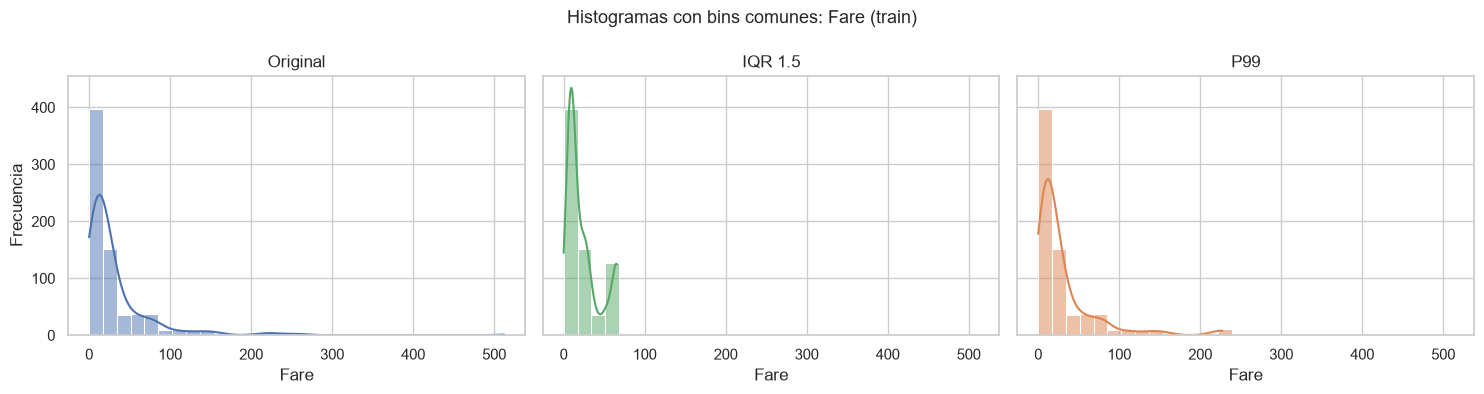

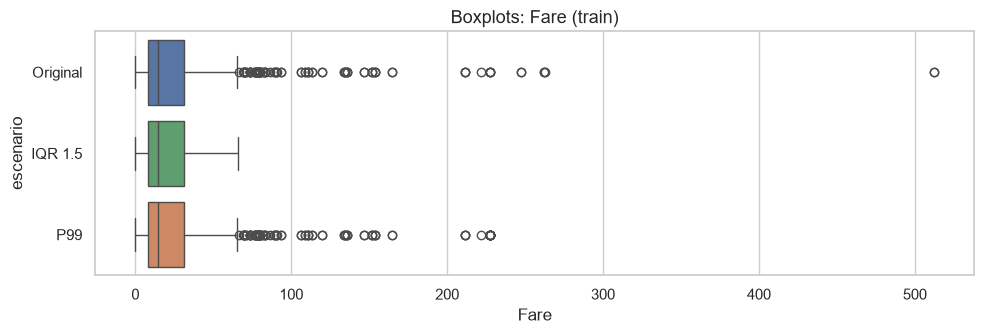

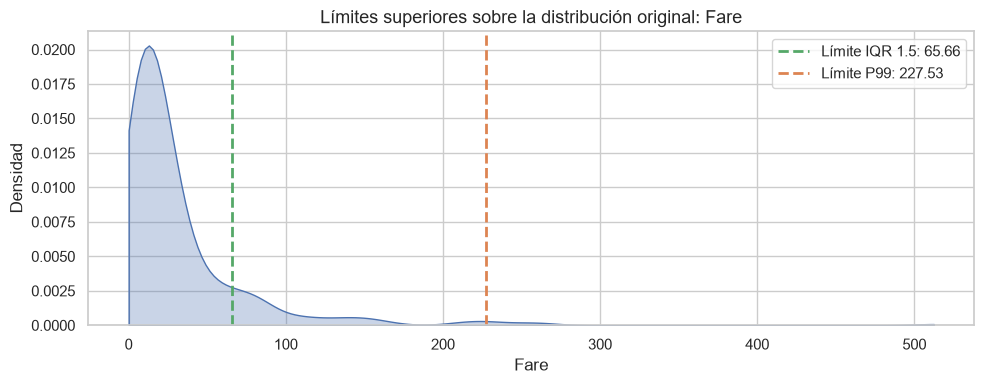

In [16]:
graficar_winsorizacion(
    X_train_t,
    {"IQR 1.5": X_train_t_iqr, "P99": X_train_t_p99},
    {"IQR 1.5": wins_titanic_iqr.limites_["Fare"]["sup"],
     "P99": wins_titanic_p99.limites_["Fare"]["sup"]},
    "Fare", "¿El IQR comprime la cola derecha mucho más que el P99?")

**Interpretación (Fare, train):** El límite IQR (65.66) recorta 91 valores y los concentra en un solo punto, lo que se ve como una barra alta en el extremo derecho del histograma; el boxplot queda sin valores fuera de la caja. El límite P99 (227.53) recorta solo 7 valores y conserva la forma de la cola. En ambos casos la caja y la mediana no cambian, porque solo se modifica la cola superior. El boxplot del P99 sigue mostrando puntos por encima de ~65 porque aplica su propia regla de 1.5·IQR, no el límite de winsorización. Estas figuras describen el cambio en la distribución, no su efecto en el modelo.


Age: ¿Se aprecia algún cambio en el centro o en la forma de la distribución al recortar a los 6 pasajeros mayores?


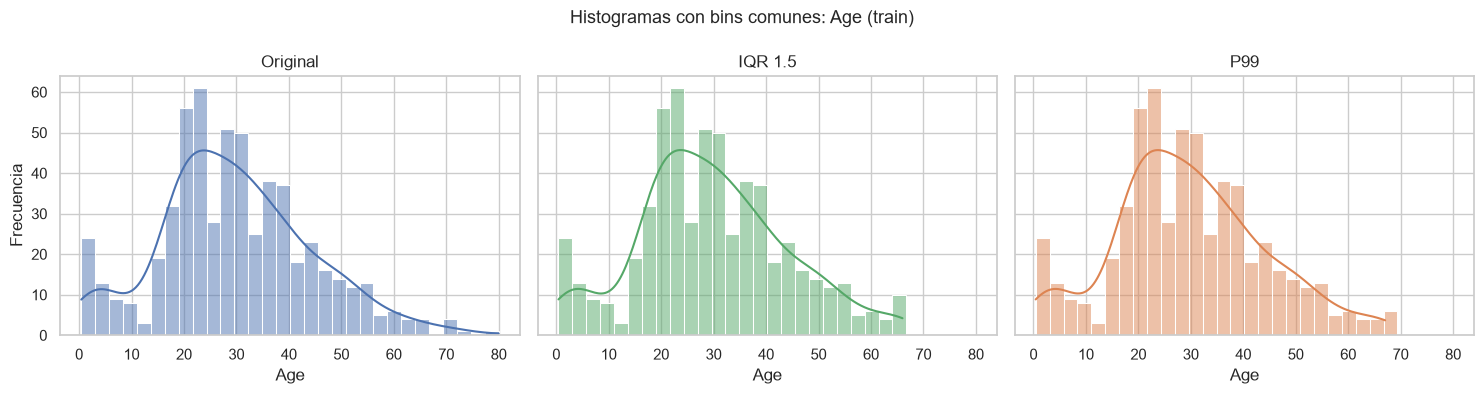

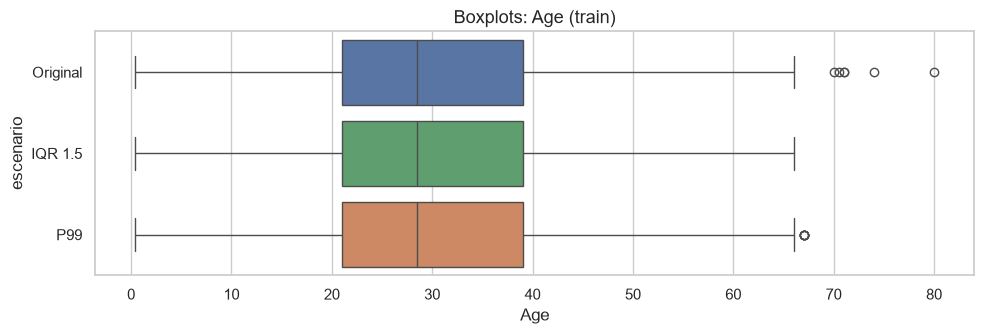

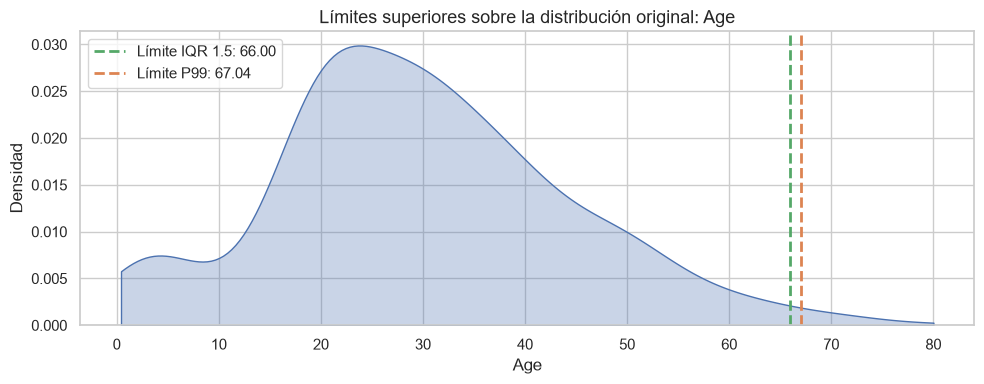

In [17]:
# [Asistido por IA - Gemini, revisado]
graficar_winsorizacion(
    X_train_t,
    {"IQR 1.5": X_train_t_iqr, "P99": X_train_t_p99},
    {"IQR 1.5": wins_titanic_iqr.limites_["Age"]["sup"],
     "P99": wins_titanic_p99.limites_["Age"]["sup"]},
    "Age", "¿Se aprecia algún cambio en el centro o en la forma de la distribución al recortar a los 6 pasajeros mayores?")

**Interpretación (Age, train):** Ambos criterios recortan a los mismos 6 pasajeros (límites 66.00 y 67.04), que quedan apilados en el límite: en el histograma IQR el último intervalo pasa de ~4 a ~10 pasajeros. La forma de la distribución, la caja y la mediana (28.5) no cambian. En el boxplot, el criterio IQR no deja valores fuera de los bigotes, mientras que con P99 los 6 valores recortados (67.04) siguen apareciendo como un punto, porque la cerca del boxplot (66.00) no se modificó. La densidad original muestra una concentración legítima de niños entre 0 y 10 años, que no se toca porque la winsorización es solo superior. El efecto descriptivo es marginal (media -0.2%, desviación -1.2% a -1.4%); su efecto en el modelo se evaluará en la sección de desempeño.


MonthlyCharges: ¿Se aprecia algún cambio visible en una variable sin outliers por IQR?


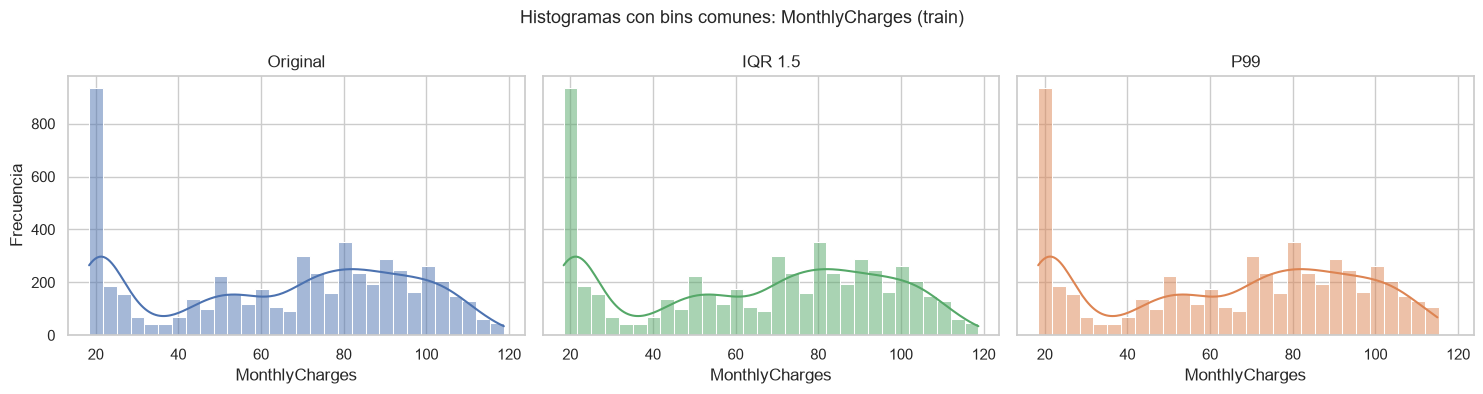

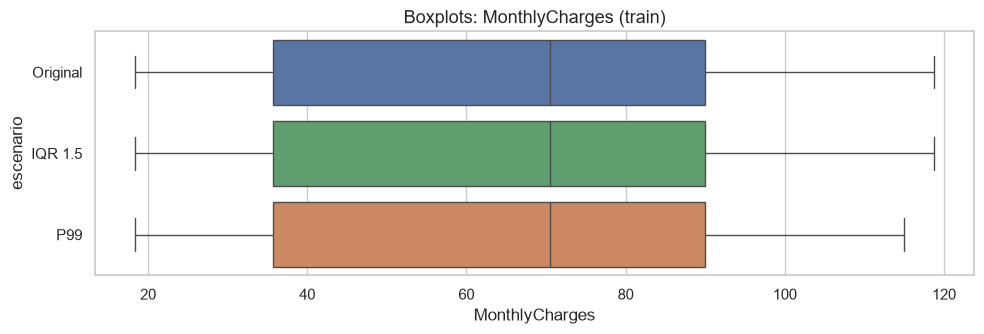

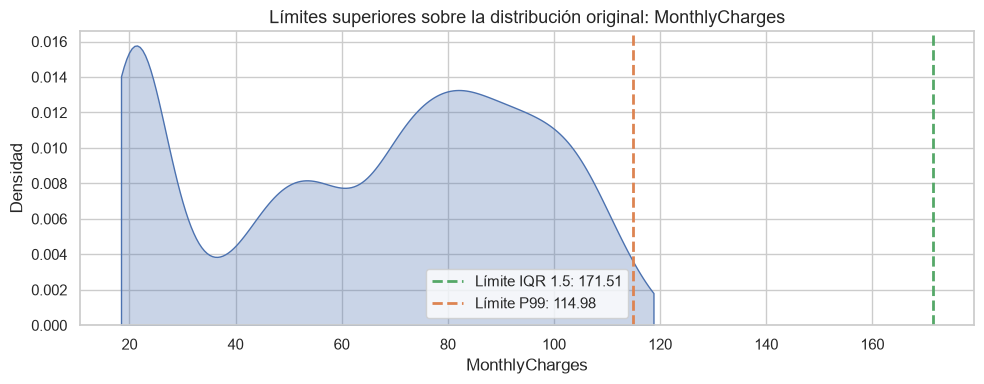

In [18]:
# [Asistido por IA - Gemini, revisado]
graficar_winsorizacion(
    X_train_c,
    {"IQR 1.5": X_train_c_iqr, "P99": X_train_c_p99},
    {"IQR 1.5": wins_telco_iqr.limites_["MonthlyCharges"]["sup"],
     "P99": wins_telco_p99.limites_["MonthlyCharges"]["sup"]},
    "MonthlyCharges", "¿Se aprecia algún cambio visible en una variable sin outliers por IQR?")

**Interpretación (MonthlyCharges, train; caso de control):** El criterio IQR 1.5 no recorta ningún valor, porque su límite (171.51) queda muy por encima del máximo observado (118.75), y su histograma y boxplot son idénticos a los originales. El criterio P99 recorta 57 valores (1.0%) al límite 114.98, que se apilan en el último intervalo; la media cambia -0.02% y la mediana (70.5) no cambia. Ningún boxplot muestra valores fuera de los bigotes, por lo que la variable no presenta valores atípicos según la regla del IQR. La distribución es multimodal, con un grupo grande de clientes en cargos bajos (~20) que corresponde a un segmento legítimo del negocio. El efecto descriptivo de la winsorización es despreciable; su efecto en el modelo se evaluará en la sección de desempeño.

In [19]:
tc = pd.to_numeric(df_telco["TotalCharges"], errors="coerce")
print("Nulos:", tc.isna().sum())
print(df_telco.loc[tc.isna(), "tenure"].value_counts())

Nulos: 11
tenure
0    11
Name: count, dtype: int64


## 8. Impacto en el modelo (preprocesamiento PROVISIONAL)

In [20]:
# [Asistido por IA - Gemini, revisado] PREPROCESAMIENTO PROVISIONAL
# Imputación provisional (mediana/moda) hasta que el equipo defina la del inciso 4.
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

ESTRATEGIA_TOTAL = "constant"   

def bloque_numerico(winsorizador=None, orden="wins_primero"):
    """wins_primero (principal): winsorizar -> imputar -> escalar
       imputar_primero (sensibilidad): imputar -> winsorizar -> escalar"""
    imp = ("imputer", SimpleImputer(strategy="median"))
    pasos = [imp]
    if winsorizador is not None:
        pasos = ([("wins", winsorizador), imp] if orden == "wins_primero"
                 else [imp, ("wins", winsorizador)])
    return Pipeline(pasos + [("scaler", StandardScaler())])

def bloque_categorico():
    return Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

def crear_prep_titanic(wins=None, orden="wins_primero"):
    return ColumnTransformer([
        ("num_wins",  bloque_numerico(wins, orden), ["Age", "Fare"]),
        ("num_otras", bloque_numerico(None),        ["SibSp", "Parch"]),
        ("cat",       bloque_categorico(),          ["Sex", "Embarked", "Pclass"]),
    ], remainder="drop")

# Telco: solo MonthlyCharges se winsoriza (caso de control)
num_wins_c = ["MonthlyCharges"]
cat_c = [c for c in X_train_c.columns
         if c not in num_wins_c + ["tenure", "TotalCharges", "customerID"]]

def crear_prep_telco(wins=None, orden="wins_primero"):
    imp_total = Pipeline([
        ("imputer", SimpleImputer(strategy=ESTRATEGIA_TOTAL, fill_value=0)),
        ("scaler", StandardScaler())])
    return ColumnTransformer([
        ("num_wins", bloque_numerico(wins, orden), num_wins_c),
        ("tenure",   bloque_numerico(None),        ["tenure"]),
        ("total",    imp_total,                    ["TotalCharges"]),
        ("cat",      bloque_categorico(),          cat_c),
    ], remainder="drop")

W_IQR = lambda: Winsorizador(metodo="iqr", factor=1.5, colas="superior")
W_P99 = lambda: Winsorizador(metodo="percentil", percentil=99, colas="superior")
W_P95 = lambda: Winsorizador(metodo="percentil", percentil=95, colas="superior")

# --- Verificación rápida (recibe X_train SIN tratar) ---
p = crear_prep_titanic(W_IQR()); Xt = p.fit_transform(X_train_t)
lims = p.named_transformers_["num_wins"].named_steps["wins"].limites_
print("Titanic límites:", {k: round(v["sup"], 2) for k, v in lims.items()},
      "| shape:", Xt.shape, "| NaN:", int(np.isnan(Xt).sum()))
p = crear_prep_telco(W_IQR()); Xc = p.fit_transform(X_train_c)
lims = p.named_transformers_["num_wins"].named_steps["wins"].limites_
print("Telco límites:", {k: round(v["sup"], 2) for k, v in lims.items()},
      "| shape:", Xc.shape, "| NaN:", int(np.isnan(Xc).sum()))

Titanic límites: {'Age': np.float64(66.0), 'Fare': np.float64(65.66)} | shape: (712, 12) | NaN: 0
Telco límites: {'MonthlyCharges': np.float64(171.51)} | shape: (5634, 46) | NaN: 0


Celda 2: Modelos, folds y funciones de evaluación

In [21]:
# [Asistido por IA - Gemini, revisado]
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

SEMILLA = 42
UMBRAL_DELTA = 0.01   # FIJADO ANTES DE MEDIR: relevante si |Δ medio| > 0.01 y |Δ medio| > desv. de las diferencias

y_t = y_train_t.astype(int)
y_c = (y_train_c == "Yes").astype(int)

# Mismos folds en TODOS los escenarios (lista fija, no se vuelven a generar)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)
folds_t = list(rskf.split(X_train_t, y_t))
folds_c = list(rskf.split(X_train_c, y_c))

# Sin class_weight ni remuestreo (el balanceo es el inciso 6)
modelos = {
    "LogReg": lambda: LogisticRegression(max_iter=1000, random_state=SEMILLA),
    "RandForest": lambda: RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=1),
}

SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1",
           "recall": "recall", "precision": "precision", "accuracy": "accuracy"}

def evaluar(X, y, escenarios, folds):
    filas = {}
    for esc, f_prep in escenarios.items():
        for mod, f_mod in modelos.items():
            pipe = Pipeline([("prep", f_prep()), ("modelo", f_mod())])
            res = cross_validate(pipe, X, y, cv=folds, scoring=SCORING,
                                 n_jobs=-1, error_score="raise")   # si falla en Windows, usa n_jobs=1
            filas[(esc, mod)] = pd.DataFrame({m: res[f"test_{m}"] for m in SCORING})
    return filas

def tabla_medias(filas):
    t = pd.DataFrame({k: v.mean() for k, v in filas.items()}).T
    t.index.names = ["escenario", "modelo"]
    return t.round(4)

def tabla_diferencias(filas, metricas, base="Original"):
    out = []
    for (esc, mod), df in filas.items():
        if esc == base:
            continue
        d = df[metricas] - filas[(base, mod)][metricas]      # diferencia pareada por fold
        for m in metricas:
            media, sd = d[m].mean(), d[m].std()
            out.append({"escenario": esc, "modelo": mod, "métrica": m,
                        "Δ_media": media, "Δ_desv": sd,
                        "relevante": abs(media) > UMBRAL_DELTA and abs(media) > sd})
    return pd.DataFrame(out).round(4)

In [22]:
print("Folds Titanic:", len(folds_t), "| Folds Telco:", len(folds_c))
print("Tamaño de validación (Titanic, primer fold):", len(folds_t[0][1]))

Folds Titanic: 15 | Folds Telco: 15
Tamaño de validación (Titanic, primer fold): 143


Celda 3: Titanic

In [23]:

escenarios_t = {
    "Original":    lambda: crear_prep_titanic(None),
    "IQR 1.5":     lambda: crear_prep_titanic(W_IQR()),
    "P99":         lambda: crear_prep_titanic(W_P99()),
    "P95 (sens.)": lambda: crear_prep_titanic(W_P95()),
    "IQR imputar-primero (sens.)": lambda: crear_prep_titanic(W_IQR(), orden="imputar_primero"),
}
res_t = evaluar(X_train_t, y_t, escenarios_t, folds_t)   # recibe X_train SIN tratar
print(tabla_medias(res_t).to_string())
print(tabla_diferencias(res_t, ["f1", "roc_auc"]).to_string(index=False))

                                        roc_auc  pr_auc      f1  recall  precision  accuracy
escenario                   modelo                                                          
Original                    LogReg       0.8541  0.8344  0.7327  0.7056     0.7687    0.8029
                            RandForest   0.8617  0.8190  0.7348  0.7264     0.7475    0.7996
IQR 1.5                     LogReg       0.8582  0.8369  0.7155  0.6947     0.7443    0.7889
                            RandForest   0.8595  0.8196  0.7321  0.7216     0.7484    0.7982
P99                         LogReg       0.8544  0.8341  0.7327  0.7056     0.7687    0.8029
                            RandForest   0.8620  0.8179  0.7380  0.7264     0.7546    0.8029
P95 (sens.)                 LogReg       0.8568  0.8344  0.7244  0.6959     0.7625    0.7978
                            RandForest   0.8617  0.8211  0.7341  0.7264     0.7461    0.7987
IQR imputar-primero (sens.) LogReg       0.8584  0.8370  0.7157  0.693

In [25]:
# [Asistido por IA - Gemini, revisado] Ablación: IQR 1.5 solo sobre Fare
esc_ab = {"IQR solo Fare": lambda: crear_prep_titanic(
    Winsorizador(columnas=["Fare"], metodo="iqr", factor=1.5, colas="superior"))}
res_ab = evaluar(X_train_t, y_t, esc_ab, folds_t)
dif = tabla_diferencias({**res_t, **res_ab}, ["f1", "roc_auc"])
print(dif[dif["escenario"] == "IQR solo Fare"].to_string(index=False))

    escenario     modelo métrica  Δ_media  Δ_desv  relevante
IQR solo Fare     LogReg      f1  -0.0172  0.0105       True
IQR solo Fare     LogReg roc_auc   0.0032  0.0064      False
IQR solo Fare RandForest      f1  -0.0011  0.0134      False
IQR solo Fare RandForest roc_auc  -0.0019  0.0035      False


In [26]:
p1 = X_train_t[X_train_t["Pclass"] == 1].copy()
p1["Survived"] = y_train_t.loc[p1.index]
p1["Fare_recortado"] = p1["Fare"] > 65.66
print(p1.groupby("Fare_recortado")["Survived"].agg(["count", "mean"]))
print(X_train_t[X_train_t["Fare"] > 65.66]["Pclass"].value_counts())

                count      mean
Fare_recortado                 
False              90  0.522222
True               81  0.790123
Pclass
1    81
3     5
2     5
Name: count, dtype: int64


**Ablación de Fare y análisis de Pclass (Titanic, train):**
Aplicar el límite IQR 1.5 solo a Fare reproduce la caída de F1 de la Regresión Logística observada al winsorizar Age y Fare (Δ = -0.017, desviación de las diferencias 0.011), mientras que el ROC-AUC no cambia de forma relevante (+0.003) y Random Forest no muestra efecto (Δ F1 = -0.001). De los 91 valores de Fare por encima de 65.66, 81 corresponden a primera clase, y dentro de esa clase la supervivencia es 79.0% (n = 81) para tarifas por encima del límite frente a 52.2% (n = 90) para las demás. Estos resultados son consistentes con que el recorte por IQR comprime diferencias de tarifa con valor predictivo dentro de primera clase, pero no prueban la causa: la tarifa puede estar asociada a otros factores (cubierta, familia, sexo), el análisis es descriptivo y los tamaños de grupo son pequeños.

Celda 4: Telco

In [24]:
# [Asistido por IA - Gemini, revisado]
escenarios_c = {
    "Original":    lambda: crear_prep_telco(None),
    "IQR 1.5":     lambda: crear_prep_telco(W_IQR()),
    "P99":         lambda: crear_prep_telco(W_P99()),
    "P95 (sens.)": lambda: crear_prep_telco(W_P95()),
}
res_c = evaluar(X_train_c, y_c, escenarios_c, folds_c)
print(tabla_medias(res_c).to_string())
print(tabla_diferencias(res_c, ["pr_auc", "roc_auc"]).to_string(index=False))

# Prueba de cordura: IQR no recorta nada en Telco, así que debe ser IDÉNTICO al original
for mod in modelos:
    assert np.allclose(res_c[("IQR 1.5", mod)].values, res_c[("Original", mod)].values), \
        f"IQR ≠ Original en {mod}: hay un error en el pipeline"
print("Cordura OK: Telco IQR idéntico al original")

                        roc_auc  pr_auc      f1  recall  precision  accuracy
escenario   modelo                                                          
Original    LogReg       0.8462  0.6610  0.5942  0.5454     0.6542    0.8027
            RandForest   0.8243  0.6154  0.5555  0.4923     0.6385    0.7912
IQR 1.5     LogReg       0.8462  0.6610  0.5942  0.5454     0.6542    0.8027
            RandForest   0.8243  0.6154  0.5555  0.4923     0.6385    0.7912
P99         LogReg       0.8462  0.6610  0.5940  0.5449     0.6545    0.8027
            RandForest   0.8240  0.6154  0.5541  0.4910     0.6375    0.7908
P95 (sens.) LogReg       0.8462  0.6611  0.5949  0.5458     0.6553    0.8031
            RandForest   0.8235  0.6149  0.5552  0.4943     0.6349    0.7903
  escenario     modelo métrica  Δ_media  Δ_desv  relevante
    IQR 1.5     LogReg  pr_auc   0.0000  0.0000      False
    IQR 1.5     LogReg roc_auc   0.0000  0.0000      False
    IQR 1.5 RandForest  pr_auc   0.0000  0.0000      

Gráficas 

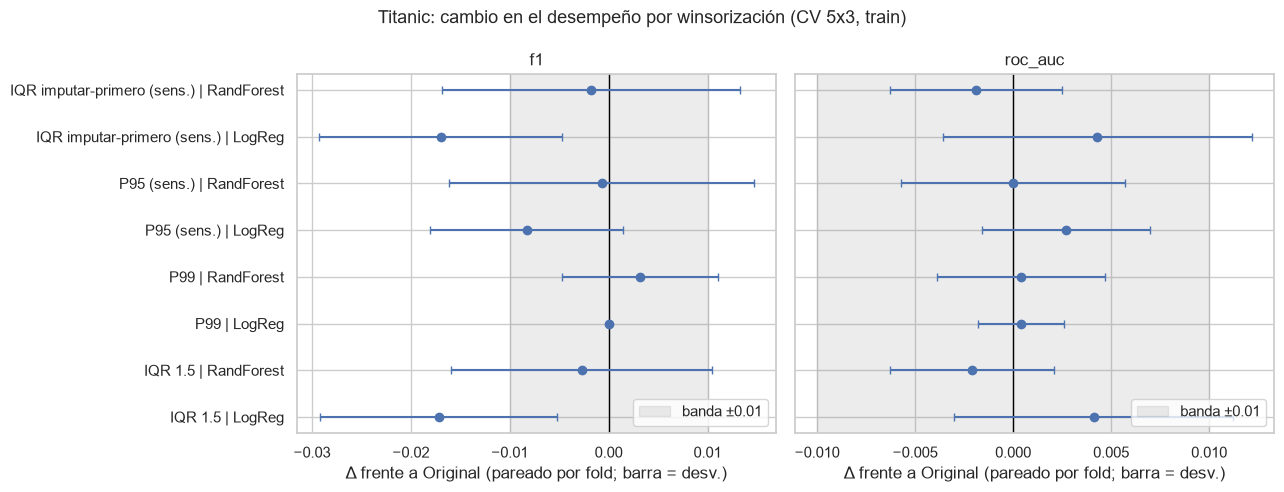

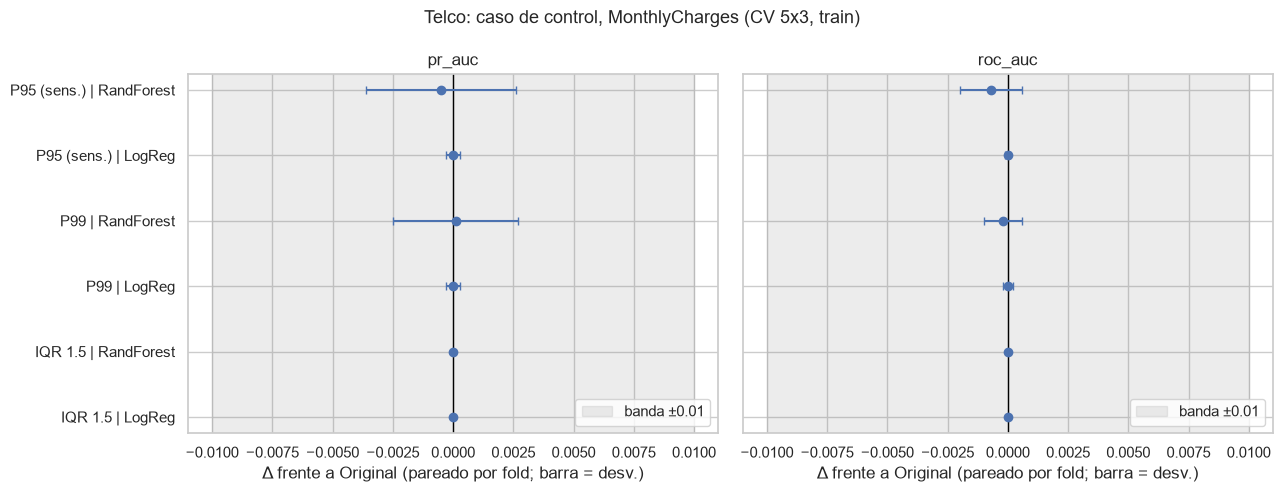

In [27]:

import numpy as np
import matplotlib.pyplot as plt

def grafica_deltas(res, metricas, titulo):
    d = tabla_diferencias(res, metricas)
    fig, axes = plt.subplots(1, len(metricas), figsize=(6.5 * len(metricas), 5), sharey=True)
    for ax, m in zip(np.atleast_1d(axes), metricas):
        sub = d[d["métrica"] == m].reset_index(drop=True)
        y = np.arange(len(sub))
        ax.axvspan(-UMBRAL_DELTA, UMBRAL_DELTA, color="grey", alpha=0.15,
                   label=f"banda ±{UMBRAL_DELTA}")
        ax.axvline(0, color="black", lw=1)
        ax.errorbar(sub["Δ_media"], y, xerr=sub["Δ_desv"], fmt="o", capsize=3)
        ax.set_yticks(y)
        ax.set_yticklabels(sub["escenario"] + " | " + sub["modelo"])
        ax.set_title(m); ax.set_xlabel("Δ frente a Original (pareado por fold; barra = desv.)")
        ax.invert_yaxis(); ax.legend(loc="lower right")
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout(); plt.show()

grafica_deltas(res_t, ["f1", "roc_auc"], "Titanic: cambio en el desempeño por winsorización (CV 5x3, train)")
grafica_deltas(res_c, ["pr_auc", "roc_auc"], "Telco: caso de control, MonthlyCharges (CV 5x3, train)")

Matriz de confusión

In [ ]:
# [Asistido por IA - Gemini, revisado] Descriptivo: no se usa para decidir
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (nombre, f) in zip(axes, {"Original": lambda: crear_prep_titanic(None),
                                  "IQR 1.5": lambda: crear_prep_titanic(W_IQR())}.items()):
    pipe = Pipeline([("prep", f()), ("modelo", modelos["LogReg"]())]).fit(X_train_t, y_t)
    ConfusionMatrixDisplay.from_estimator(pipe, X_test_t, y_test_t.astype(int),
                                          ax=ax, colorbar=False)
    ax.set_title(f"Titanic LogReg: {nombre} (test)")
plt.tight_layout(); plt.show()